# Part 2 of 6: Custom CNN & ResNet18: Models, Training & Tuning

This notebook covers Sections 7–9: the custom CNN and ResNet18, the training engine, hyperparameter tuning, ablations and the selection of both models on the validation set. The ViT is trained in notebook 03.

Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from torchinfo import summary

from plantdisease.config import TRAIN_CONFIG, out_path
from plantdisease.data.dataset import prepare
from plantdisease.evaluate import mean_sd
from plantdisease.experiments import (
    BASE_CNN,
    BASE_RESNET,
    CNN_EXPERIMENTS,
    RESNET_EXPERIMENTS,
    changes_table,
    config_of,
    save_selected,
)
from plantdisease.models import build_model
from plantdisease.plots import finish
from plantdisease.train import run

data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache
TUNING_SEED = TRAIN_CONFIG["tuning_seed"]  # one seed for the tuning runs and ablations

## 7. Models

| Model | Type | Idea |
|---|---|---|
| **Custom CNN** | trained from scratch | 4 × (Conv 3×3 → BatchNorm → ReLU → MaxPool), global average pooling, dropout, linear |
| **SE-CNN** | trained from scratch + attention | the same CNN with a **Squeeze-and-Excitation** block after every conv layer. SE squeezes each channel to one number (global average), passes the result through a small bottleneck MLP and uses the sigmoid output to **re-weight the channels**. This is a cheap form of attention that lets the network emphasise lesion-detecting filters (Hu et al., 2018). |
| **ResNet18** | transfer learning (CNN) | ImageNet-pretrained, new 4-class head |
| **ViT-B/16** | transfer learning (transformer) | notebook 03 |

`set_trainable` implements the freezing used for **two-stage fine-tuning**. In the first stage only the new head is trained, so that the randomly initialised layer does not send large, noisy gradients into the pre-trained backbone. In the second stage the backbone is unfrozen and trained with a smaller learning rate. The models are defined in `plantdisease/models.py` (shared with the later notebooks, which rebuild the models from their checkpoints). Their code and layer shapes are shown below.

### Training recipes

Every model is trained with a **recipe** (`RunConfig`, `plantdisease/experiments.py`): architecture, learning rate, batch size, dropout, augmentation, class weights, learning-rate schedule, weight decay, maximum epochs and early-stopping patience, and for pre-trained models the head-only epochs and their learning rates. The base recipes of the custom CNN and of ResNet18 (`BASE_CNN`, `BASE_RESNET`) are defined in the same file and shown below; Section 9 derives all experiments from them. The maximum epochs and the patience can be set with the environment variables `EPOCHS_*` and `PATIENCE_*` (see the README).

In [2]:
# all settings of both base recipes (settings that a recipe does not list keep their default)
pd.DataFrame(
    {"custom CNN": BASE_CNN.model_dump(), "ResNet18": BASE_RESNET.model_dump()}
)

,custom CNN,ResNet18
arch,se_cnn,resnet18
lr,0.001,0.0001
batch_size,32,32
dropout,0.3,0.0
augment,True,True
class_weights,True,True
scheduler,cosine,cosine
weight_decay,0.0001,0.0001
epochs,50,20
patience,10,5


The tables below are `torchinfo.summary` of each model for one 224 × 224 RGB image: the output shape and the number of parameters of every layer, and the totals. The global average pooling in `CustomCNN.forward` has no module of its own: it turns the last feature map (256 × 14 × 14) into a vector of 256 values, which is the input of the `dropout` layer.

**Custom CNN**

In [3]:
summary(build_model(BASE_CNN.variant(arch="cnn")), input_size=(1, 3, 224, 224), depth=4)

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 256, 14, 14]          --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         864
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         --
│    └─MaxPool2d: 2-4                    [1, 32, 112, 112]         --
│    └─Conv2d: 2-5                       [1, 64, 112, 112]         18,432
│    └─BatchNorm2d: 2-6                  [1, 64, 112, 112]         128
│    └─ReLU: 2-7                         [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-8                    [1, 64, 56, 56]           --
│    └─Conv2d: 2-9                       [1, 128, 56, 56]          73,728
│    └─BatchNorm2d: 2-10                 [1, 128, 56, 56]          256
│    └─ReLU: 2-11                        [1, 128, 56, 56]          --
│   

**SE-CNN** (an SEBlock after every ReLU keeps the shape and adds parameters)

In [4]:
summary(build_model(BASE_CNN), input_size=(1, 3, 224, 224), depth=4)

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 256, 14, 14]          --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         864
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         --
│    └─SEBlock: 2-4                      [1, 32, 224, 224]         --
│    │    └─Sequential: 3-1              [1, 32]                   --
│    │    │    └─Linear: 4-1             [1, 4]                    132
│    │    │    └─ReLU: 4-2               [1, 4]                    --
│    │    │    └─Linear: 4-3             [1, 32]                   160
│    │    │    └─Sigmoid: 4-4            [1, 32]                   --
│    └─MaxPool2d: 2-5                    [1, 32, 112, 112]         --
│    └─Conv2d: 2-6                       [1, 64, 112, 112]         18,432
│    └─B

**ResNet18**

In [5]:
summary(
    build_model(BASE_RESNET, pretrained=False), input_size=(1, 3, 224, 224), depth=3
)

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 4]                    --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│

## 8. Training Engine

`run(name, data, seeds)` (`plantdisease/train.py`) trains the recipe of a run name with every seed and returns one history per seed. One run:
- **AdamW** (Adam with decoupled weight decay), optionally with a **cosine learning-rate schedule** stepped every batch;
- **two-stage fine-tuning** for pre-trained models: `head_epochs` epochs training only the head at `head_lr`, then fine-tuning; in the second stage the head and the backbone can have different learning rates (used by the ViT);
- optional class-weighted loss, **gradient clipping** (norm 1) for stability, and **mixed precision** on CUDA;
- **early stopping**: training stops when the validation macro-F1 has not improved for `patience` epochs (`patience` of the recipes in Section 7: 5 epochs for every model). The count starts with the last training stage, so a pre-trained model always fine-tunes for at least `patience` epochs. A cosine schedule keeps its full length, so a run that stops early ends before its learning rate reaches zero;
- **checkpointing**: the weights of the epoch with the best validation macro-F1 are saved (ties keep the earlier epoch). The history and the exact configuration are saved as JSON. If a run with the same configuration already exists, it is loaded instead of retrained;
- **training cost**: per epoch the training time without validation (measured after the GPU has finished), and the number of trainable parameters.

## 9. Hyperparameter Tuning & Ablations (Validation Set Only)

The runs of 9.1 and 9.2 use training seed 62 and are compared by the **best validation macro-F1**. Section 9.3 repeats the best candidates with all training seeds and selects the final models.

**9.1 Custom CNN.** The full recipe is: SE attention, augmentation, dropout 0.3, class-weighted loss, cosine schedule, batch size 32, AdamW (weight decay 1e-4).
- We first sweep the **learning rate** (3e-4, 1e-3, 3e-3).
- Starting from the full recipe at lr 1e-3, we then **remove one component at a time** (ablation). This shows how much each component contributes. It covers the architecture (attention), augmentation, regularisation (dropout), class balancing and the scheduler, plus a **batch-size** variation.

**9.2 Fine-tuning strategies (ResNet18).**
- (a) **frozen backbone**: head only;
- (b) **full fine-tuning with a constant learning rate**;
- (c) **two-stage fine-tuning with a cosine schedule**, at two backbone learning rates;
- (d) starting from (c) at lr 1e-4: **batch size 64**, **no augmentation** and **weight decay 1e-2**.

All experiments are listed in Section 9.0.

### 9.0 The experiments

All experiments of 9.1 and 9.2 are defined in `plantdisease/experiments.py` (`CNN_EXPERIMENTS`, `RESNET_EXPERIMENTS`) as changes of the base recipes of Section 7. Every notebook finds the recipe of a run by its name (`config_of`).

In [6]:
# what every experiment changes relative to its base recipe
display(changes_table(CNN_EXPERIMENTS, BASE_CNN))
changes_table(RESNET_EXPERIMENTS, BASE_RESNET)

,changes from the base recipe
SE-CNN (full recipe),(base recipe)
SE-CNN lr=3e-4,lr=0.0003
SE-CNN lr=3e-3,lr=0.003
CNN (no attention),arch=cnn
SE-CNN no augmentation,augment=False
SE-CNN no dropout,dropout=0.0
SE-CNN no class weights,class_weights=False
SE-CNN constant lr,scheduler=constant
SE-CNN batch size 64,batch_size=64


,changes from the base recipe
ResNet18 frozen backbone,"scheduler=constant, head_epochs=20"
"ResNet18 full FT, constant lr","scheduler=constant, head_epochs=0"
"ResNet18 two-stage + cosine, lr=1e-4",(base recipe)
"ResNet18 two-stage + cosine, lr=3e-4",lr=0.0003
ResNet18 batch size 64,batch_size=64
ResNet18 no augmentation,augment=False
ResNet18 weight decay 1e-2,weight_decay=0.01


In [7]:
histories = {name: run(name, data, seeds=[TUNING_SEED])[0] for name in CNN_EXPERIMENTS}


===== SE-CNN (full recipe) (seed 62) =====
Epoch 1/50 [finetune] | train loss 0.4981 acc 0.8172 | val loss 1.1832 acc 0.6171 macro-F1 0.5679 | 17s
Epoch 2/50 [finetune] | train loss 0.3250 acc 0.8886 | val loss 0.3095 acc 0.8553 macro-F1 0.8128 | 5s
Epoch 3/50 [finetune] | train loss 0.2909 acc 0.8952 | val loss 0.7006 acc 0.7342 macro-F1 0.7361 | 5s
Epoch 4/50 [finetune] | train loss 0.2261 acc 0.9224 | val loss 0.2328 acc 0.9079 macro-F1 0.8914 | 5s
Epoch 5/50 [finetune] | train loss 0.2071 acc 0.9294 | val loss 0.1146 acc 0.9605 macro-F1 0.9572 | 6s
Epoch 6/50 [finetune] | train loss 0.2089 acc 0.9283 | val loss 0.0897 acc 0.9697 macro-F1 0.9648 | 6s
Epoch 7/50 [finetune] | train loss 0.1693 acc 0.9430 | val loss 0.0902 acc 0.9776 macro-F1 0.9738 | 6s
Epoch 8/50 [finetune] | train loss 0.1499 acc 0.9490 | val loss 0.1257 acc 0.9474 macro-F1 0.9343 | 6s
Epoch 9/50 [finetune] | train loss 0.1477 acc 0.9513 | val loss 0.0860 acc 0.9737 macro-F1 0.9680 | 6s
Epoch 10/50 [finetune] | tra

In [8]:
histories.update(
    {name: run(name, data, seeds=[TUNING_SEED])[0] for name in RESNET_EXPERIMENTS}
)


===== ResNet18 frozen backbone (seed 62) =====
Epoch 1/20 [head] | train loss 0.7035 acc 0.7631 | val loss 0.3491 acc 0.9026 macro-F1 0.8808 | 15s
Epoch 2/20 [head] | train loss 0.3390 acc 0.9031 | val loss 0.2225 acc 0.9303 macro-F1 0.9169 | 3s
Epoch 3/20 [head] | train loss 0.2903 acc 0.9068 | val loss 0.1949 acc 0.9368 macro-F1 0.9228 | 3s
Epoch 4/20 [head] | train loss 0.2447 acc 0.9255 | val loss 0.1693 acc 0.9434 macro-F1 0.9306 | 3s
Epoch 5/20 [head] | train loss 0.2153 acc 0.9289 | val loss 0.1489 acc 0.9500 macro-F1 0.9411 | 3s
Epoch 6/20 [head] | train loss 0.2076 acc 0.9323 | val loss 0.1414 acc 0.9487 macro-F1 0.9382 | 3s
Epoch 7/20 [head] | train loss 0.1989 acc 0.9360 | val loss 0.1348 acc 0.9539 macro-F1 0.9443 | 3s
Epoch 8/20 [head] | train loss 0.1888 acc 0.9365 | val loss 0.1315 acc 0.9526 macro-F1 0.9426 | 3s
Epoch 9/20 [head] | train loss 0.1953 acc 0.9334 | val loss 0.1344 acc 0.9447 macro-F1 0.9328 | 3s
Epoch 10/20 [head] | train loss 0.1727 acc 0.9425 | val loss

In [9]:
def summarize(name, h):
    # One row of the tuning table: the recipe and its best validation epoch.
    cfg = config_of(name)
    best = int(np.argmax(h.val_f1))
    return {
        "run": name,
        "arch": cfg.arch,
        "lr": cfg.lr,
        "batch": cfg.batch_size,
        "dropout": cfg.dropout,
        "augment": cfg.augment,
        "class_w": cfg.class_weights,
        "schedule": cfg.scheduler,
        "best_epoch": best + 1,
        "val_acc": h.val_acc[best],
        "val_macro_f1": h.val_f1[best],
        "train_s_per_epoch": np.mean(h.train_time),
    }


tuning = pd.DataFrame([summarize(n, h) for n, h in histories.items()]).set_index("run")
tuning.to_csv(out_path("tuning_results.csv"))

tuning.round(4)

,arch,lr,batch,dropout,augment,class_w,schedule,best_epoch,val_acc,val_macro_f1,train_s_per_epoch
run,,,,,,,,,,,
SE-CNN (full recipe),se_cnn,0.0010,32,0.3,True,True,cosine,43,0.9934,0.9923,5.5564
SE-CNN lr=3e-4,se_cnn,0.0003,32,0.3,True,True,cosine,39,0.9921,0.9901,5.5577
SE-CNN lr=3e-3,se_cnn,0.0030,32,0.3,True,True,cosine,43,0.9934,0.9918,5.3386
CNN (no attention),cnn,0.0010,32,0.3,True,True,cosine,27,0.9921,0.9901,4.2579
SE-CNN no augmentation,se_cnn,0.0010,32,0.3,False,True,cosine,30,0.9921,0.9901,5.3439
SE-CNN no dropout,se_cnn,0.0010,32,0.0,True,True,cosine,41,0.9934,0.9918,5.5174
SE-CNN no class weights,se_cnn,0.0010,32,0.3,True,False,cosine,45,0.9934,0.9923,5.6067
SE-CNN constant lr,se_cnn,0.0010,32,0.3,True,True,constant,17,0.9895,0.9871,5.5815
SE-CNN batch size 64,se_cnn,0.0010,64,0.3,True,True,cosine,50,0.9908,0.9888,5.3179


### 9.3 Do the best candidates stay on top? Selection with all seeds

Differences between neighbouring configurations are often smaller than the run-to-run variation, so a single seed cannot rank them reliably. The three best CNN variants and the two best ResNet18 variants (by the validation macro-F1 of seed 62) are therefore repeated with all training seeds. The **final models are chosen by the mean validation macro-F1 over the seeds**, shown with the standard deviation over the seeds. The test set is not used here.

In [10]:
# Model selection on the validation set: the best candidates are repeated with all training seeds
TOP_K = {"cnn": 3, "resnet18": 2}  # candidates per family
families = {"cnn": CNN_EXPERIMENTS, "resnet18": RESNET_EXPERIMENTS}
rows = []
for family, experiments in families.items():
    top = tuning.loc[list(experiments), "val_macro_f1"].nlargest(TOP_K[family]).index
    for name in top:
        scores = [max(h.val_f1) for h in run(name, data)]  # all training seeds
        rows.append(
            {
                "family": family,
                "run": name,
                f"val macro-F1 (seed {TUNING_SEED})": tuning.at[name, "val_macro_f1"],
                "mean over seeds": np.mean(scores),
                "mean ± sd": mean_sd(scores),
            }
        )
multi_seed = pd.DataFrame(rows).set_index("run")
multi_seed.to_csv(out_path("tuning_multi_seed.csv"))

selected = {}  # family -> the candidate with the best mean over the seeds
for family in families:
    best = multi_seed.loc[multi_seed.family == family, "mean over seeds"].idxmax()
    selected[family] = best
    save_selected(family, best)  # OUT_DIR/final_models.json, read by notebooks 04-06
    print(f"Selected {family}: {best}")
multi_seed.round(4)

Loaded finished run: SE-CNN (full recipe) (seed 62)

===== SE-CNN (full recipe) (seed 63) =====
Epoch 1/50 [finetune] | train loss 0.5237 acc 0.8232 | val loss 0.5270 acc 0.8026 macro-F1 0.7939 | 17s
Epoch 2/50 [finetune] | train loss 0.3099 acc 0.8895 | val loss 0.3688 acc 0.8566 macro-F1 0.8507 | 5s
Epoch 3/50 [finetune] | train loss 0.2648 acc 0.9110 | val loss 0.1871 acc 0.9368 macro-F1 0.9264 | 5s
Epoch 4/50 [finetune] | train loss 0.2284 acc 0.9243 | val loss 0.1408 acc 0.9539 macro-F1 0.9513 | 5s
Epoch 5/50 [finetune] | train loss 0.2027 acc 0.9297 | val loss 0.5069 acc 0.7882 macro-F1 0.8168 | 5s
Epoch 6/50 [finetune] | train loss 0.1963 acc 0.9357 | val loss 0.1208 acc 0.9592 macro-F1 0.9515 | 6s
Epoch 7/50 [finetune] | train loss 0.1761 acc 0.9422 | val loss 0.1443 acc 0.9526 macro-F1 0.9471 | 6s
Epoch 8/50 [finetune] | train loss 0.1530 acc 0.9476 | val loss 0.0745 acc 0.9711 macro-F1 0.9650 | 6s
Epoch 9/50 [finetune] | train loss 0.1432 acc 0.9552 | val loss 0.1297 acc 0.94

,family,val macro-F1 (seed 62),mean over seeds,mean ± sd
run,,,,
SE-CNN (full recipe),cnn,0.9923,0.9906,0.9906 ± 0.0030
SE-CNN no class weights,cnn,0.9923,0.9884,0.9884 ± 0.0053
SE-CNN lr=3e-3,cnn,0.9918,0.9910,0.9910 ± 0.0007
"ResNet18 two-stage + cosine, lr=1e-4",resnet18,1.0000,1.0000,1.0000 ± 0.0000
ResNet18 weight decay 1e-2,resnet18,1.0000,1.0000,1.0000 ± 0.0000


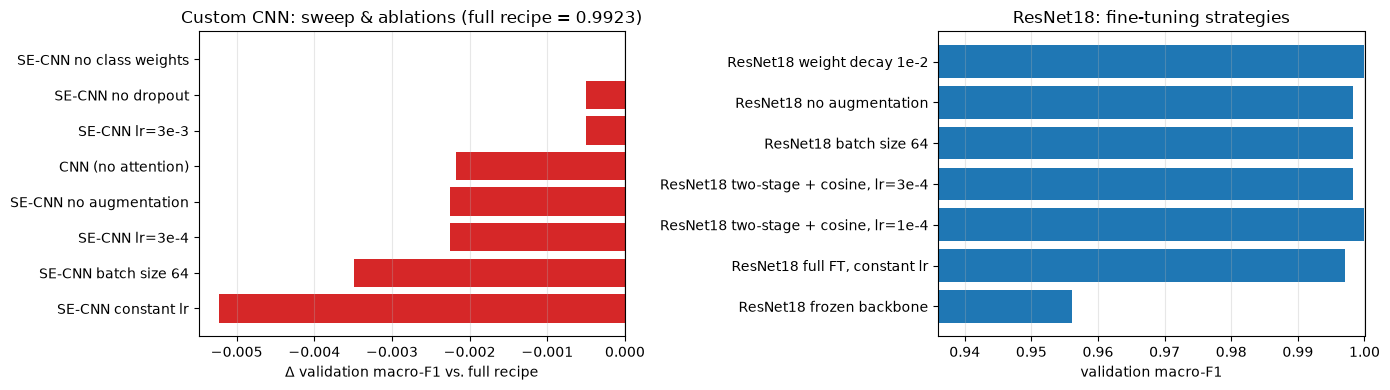

In [11]:
# Ablation chart: change in validation macro-F1 relative to the full CNN recipe
ref = tuning.loc["SE-CNN (full recipe)", "val_macro_f1"]
delta = (tuning.loc[list(CNN_EXPERIMENTS)[1:], "val_macro_f1"] - ref).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(
    delta.index,
    delta.values,
    color=["tab:red" if d < 0 else "tab:green" for d in delta.values],
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Δ validation macro-F1 vs. full recipe")
axes[0].set_title(f"Custom CNN: sweep & ablations (full recipe = {ref:.4f})")
ft = tuning.loc[list(RESNET_EXPERIMENTS), "val_macro_f1"]
axes[1].barh(ft.index, ft.values, color="tab:blue")
axes[1].set_xlim(ft.min() - 0.02, 1.0)
axes[1].set_xlabel("validation macro-F1")
axes[1].set_title("ResNet18: fine-tuning strategies")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
finish("ablations.png")

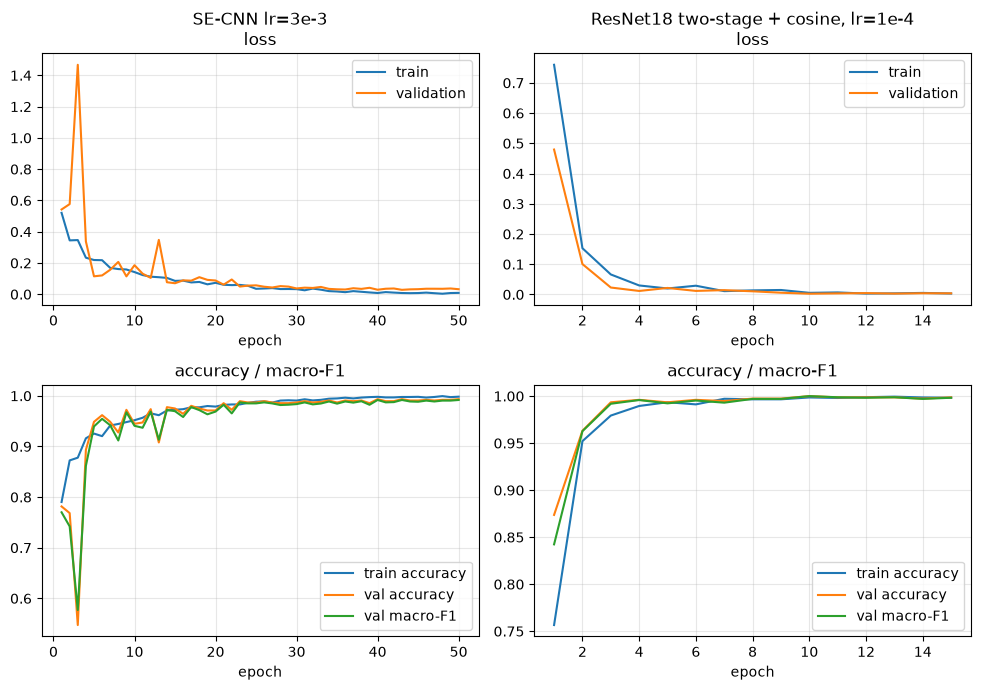

In [12]:
# Learning curves of the selected models (tuning seed)
fig, axes = plt.subplots(2, len(selected), figsize=(5 * len(selected), 7))
for col, name in enumerate(selected.values()):
    h = histories[name]
    epochs = range(1, len(h.train_loss) + 1)
    axes[0, col].plot(epochs, h.train_loss, label="train")
    axes[0, col].plot(epochs, h.val_loss, label="validation")
    axes[0, col].set_title(f"{name}\nloss")
    axes[1, col].plot(epochs, h.train_acc, label="train accuracy")
    axes[1, col].plot(epochs, h.val_acc, label="val accuracy")
    axes[1, col].plot(epochs, h.val_f1, label="val macro-F1")
    axes[1, col].set_title("accuracy / macro-F1")
    for ax in axes[:, col]:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
finish("learning_curves.png")